# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

print("Vocabulary size:", len(tokenizer.word_index))
print("Padded shape:", tuple(X.shape))

ModuleNotFoundError: No module named 'tensorflow'

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

**Changes from the starter code:**
- `nn.RNN(16, 32, batch_first=True)`: by default `nn.RNN` expects `(sequence, batch, features)`, but `X` is `(batch, sequence)`. Without `batch_first=True` the RNN reads the 168 *questions* as one long sequence (each word position becomes a "batch"), so it never reads the words of one question in order.
- Padding is masked before the softmax, so the zeros added in Step 3 get **no** attention and the weights of the real words add up to 1.

In [ ]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, tokens):
        x, _ = self.rnn(self.emb(tokens))
        scores = self.att(x).masked_fill((tokens == 0).unsqueeze(-1), float("-inf"))  # ignore padding
        weights = torch.softmax(scores, dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

`optimizer.zero_grad()` is added so the gradients from one epoch are not added to the next one.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #reset gradients from the previous epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

with torch.no_grad():
    accuracy = (model(X)[0].argmax(1) == y).float().mean().item()

print("Training finished!")
print(f"Final loss: {loss.item():.4f}")
print(f"Training accuracy: {accuracy:.2%}")

Training finished!
Final loss: 0.0688
Training accuracy: 98.81%


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

The words are taken from the tokenizer (instead of `question.split()`) so each bar lines up with the token the model actually saw.

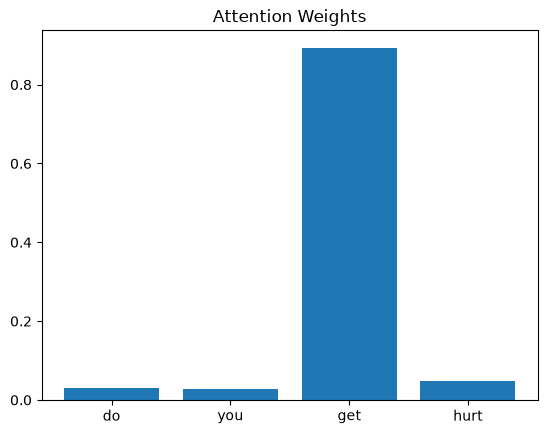

In [ ]:
def get_attention(i):
    tokens = [t for t in X[i].tolist() if t != 0]
    words = [tokenizer.index_word[t] for t in tokens]
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])
    return words, weights[0, :len(words)].tolist(), prediction.argmax(1).item()

words, weights, pred = get_attention(0)
plt.bar(words, weights)
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Q: can you cry?
   highest attention: "you" (0.94)
   predicted answer:  I don't have a body.  (correct: I don't have a body.)

Q: do you ever eat beef?
   highest attention: "eat" (0.55)
   predicted answer:  I don't need to eat.  (correct: I don't need to eat.)

Q: do you have a name?
   highest attention: "name" (0.98)
   predicted answer:  I don't have a name.  (correct: I don't have a name.)



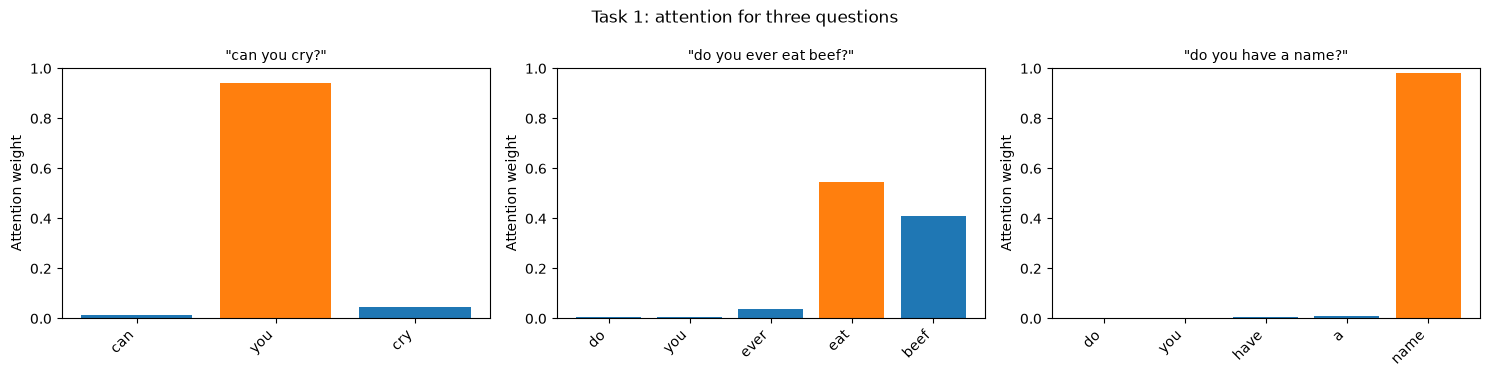

In [ ]:
answers = df.groupby("answer_id")["answer"].first()

def plot_attention(indices, title=None):
    fig, axes = plt.subplots(1, len(indices), figsize=(5 * len(indices), 3.8))
    for ax, i in zip(axes, indices):
        words, weights, pred = get_attention(i)
        top = max(range(len(words)), key=lambda k: weights[k])
        colors = ["tab:orange" if k == top else "tab:blue" for k in range(len(words))]
        ax.bar(range(len(words)), weights, color=colors)
        ax.set_xticks(range(len(words)), words, rotation=45, ha="right")
        ax.set_ylim(0, 1)
        ax.set_title(f'"{df["question"][i]}"', fontsize=10)
        ax.set_ylabel("Attention weight")
        print(f'Q: {df["question"][i]}')
        print(f'   highest attention: "{words[top]}" ({weights[top]:.2f})')
        print(f'   predicted answer:  {answers[pred]}  (correct: {answers[y[i].item()]})')
        print()
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

task1 = [7, 99, 115]  # "can you cry?", "do you ever eat beef?", "do you have a name?"
plot_attention(task1, "Task 1: attention for three questions")

**Answer (Task 1):**

| Question | Highest attention | Weight | Prediction |
|----------|-------------------|--------|------------|
| can you cry? | **you** | 0.94 | I don't have a body. ✔ |
| do you ever eat beef? | **eat** | 0.55 (beef 0.41) | I don't need to eat. ✔ |
| do you have a name? | **name** | 0.98 | I don't have a name. ✔ |

**Mostly yes, but not always.**
- In *"do you have a name?"* almost all the attention goes to **name**, the one word that tells us the question is about the bot's name. The words *do, you, have, a* appear in many other answer groups, so they get almost no weight.
- In *"do you ever eat beef?"* the attention is split between **eat** and **beef**, the two words about food. Both are useful and the filler words *do, you, ever* are ignored.
- In *"can you cry?"* the top word is **you**, not *cry*. This looks wrong at first, but the attention is placed on the **RNN hidden state**, not on the raw word. The hidden state at *you* has already read *"can you"*, and in this dataset almost every *"can you …?"* question belongs to the *"I don't have a body."* group (*can you crawl / burp / breathe / throw up / masticate …*). So the model found a shortcut: the phrase *"can you"* is enough to pick the answer, and *cry* (seen only once) adds little.

So attention usually lands on the content words that decide the answer, but it shows what helped the **model** on this small dataset, which is not always what a human would call the most important word.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Q: do you have a name?
   highest attention: "name" (0.98)
   predicted answer:  I don't have a name.  (correct: I don't have a name.)

Q: so what is your name?
   highest attention: "so" (0.94)
   predicted answer:  I don't have a name.  (correct: I don't have a name.)



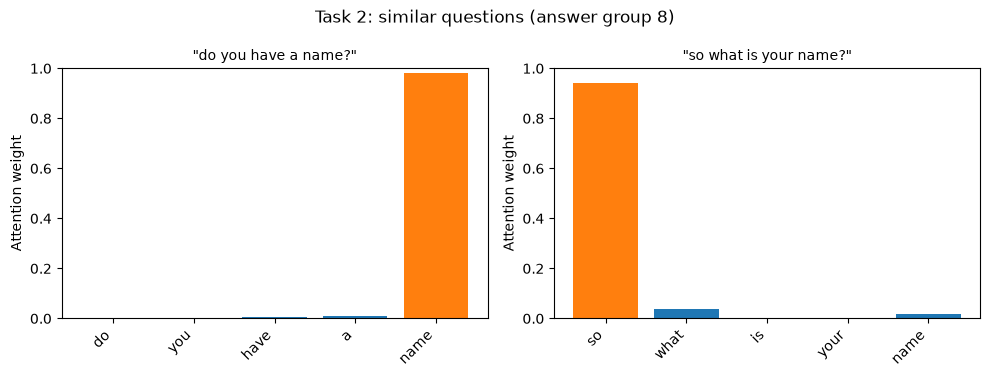

In [ ]:
# Same meaning (both mean "What is your name?"), different wording
task2 = [115, 125]  # "do you have a name?" vs "so what is your name?"
plot_attention(task2, "Task 2: similar questions (answer group 8)")

Q: how old are you?
   highest attention: "old" (0.69)
   predicted answer:  Age doesn't really apply to me.  (correct: Age doesn't really apply to me.)

Q: what's your age?
   highest attention: "your" (0.53)
   predicted answer:  Age doesn't really apply to me.  (correct: Age doesn't really apply to me.)



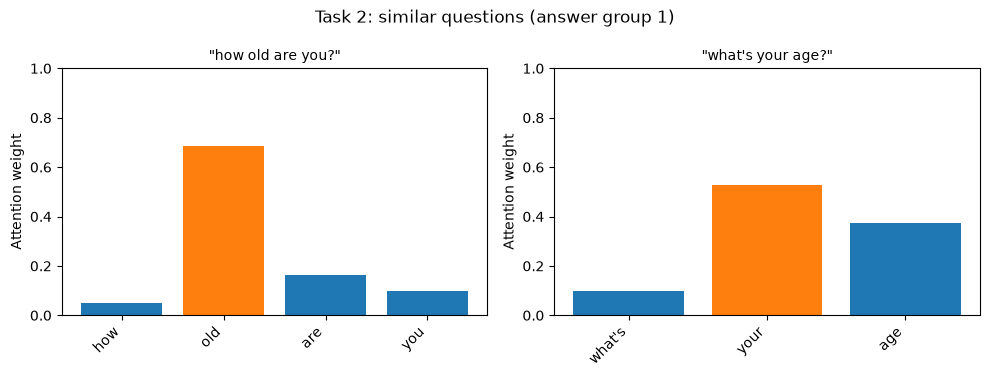

In [ ]:
# A second pair with no shared key word: "how old are you?" vs "what's your age?"
plot_attention([24, 20], "Task 2: similar questions (answer group 1)")

**Answer (Task 2):**

| Pair | Question | Highest attention | Prediction |
|------|----------|-------------------|------------|
| 1 | do you have a name? | **name** (0.98) | I don't have a name. ✔ |
| 1 | so what is your name? | **so** (0.94), *name* only 0.02 | I don't have a name. ✔ |
| 2 | how old are you? | **old** (0.69) | Age doesn't really apply to me. ✔ |
| 2 | what's your age? | **your** (0.53), *age* 0.37 | Age doesn't really apply to me. ✔ |

**The model focuses on different words**, even though each pair has the same meaning and gets the same (correct) answer.
- **Pair 1:** both questions contain *name*, but only the first one attends to it. The second one puts almost everything on **so**. In the dataset every question that starts with *"so …"* (*so what is your name, so how should I address you, so how should I refer to you, so what do you like to be called*) belongs to the name group, so the model learned *"so"* as a shortcut for that group.
- **Pair 2:** *"how old are you?"* attends to **old**, while *"what's your age?"* splits its attention between **your** and **age**. The hidden state at *your* has already read *"what's your"*, and the next word *age* also gets a large share, so the age meaning is still captured.

**What this suggests about attention:**
1. Attention is **learned from the training data**, so it picks whatever words best separate the answer groups, including shortcuts like *"so"* or *"can you"*, not only the words a human thinks are important.
2. Because the weights are over **RNN hidden states**, a high weight on a small word (*you, your, so*) can still carry the meaning of the words before it. One weight does not equal one word.
3. Different wordings can reach the same answer through different attention patterns, so attention is a helpful but **partial** explanation of the model's decision. With a much larger dataset, similar questions would be expected to focus on more similar words (*name*, *age*).